In [1]:
from julia import Main
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm
from pygraphon.estimators.HistogramEstimator import HistogramEstimator

Main.include("../src/julia_backend/source/graphest_fastgreedy.jl")

In [2]:
#Set the matrix of theta
graphon_matrix = np.array([[0.8,0.2,0.2],[0.2,0.8,0.2],[0.2,0.2,0.8]])
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,1/3)
#Draw a graph from the graphon with a given density and number of vertices, see GraphonAbstract.py
A = graphon.draw(rho = 0.7,n = 100, exchangeable=True)

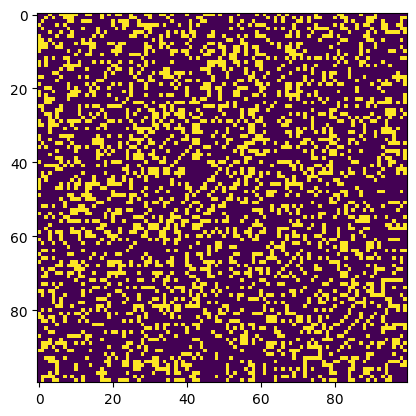

In [3]:
plt.imshow(A)

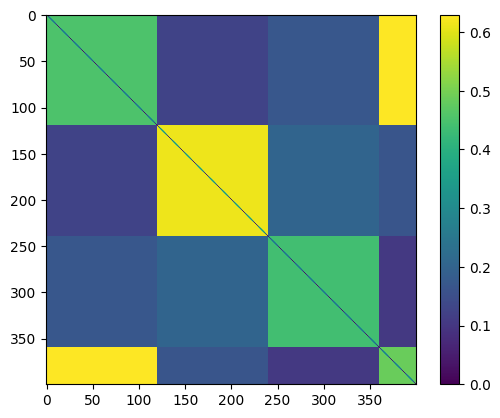

In [4]:
hist = HistogramEstimator()
hist.fit(graph= A, bandwidthHist= 0.3)
hist_approx = hist.get_graphon()
plt.imshow(hist_approx._get_edge_probabilities(400,False,True))
plt.colorbar()
plt.show()

In [ ]:
from pygraphon.estimators.utils.nethist import nethist
labels, h, trace = nethist(A,h = 33,verbose=True, trace=True)

LL: -1.6279,  5 global improvements:  17%|█▋        | 85/500 [00:14<01:12,  5.75it/s]


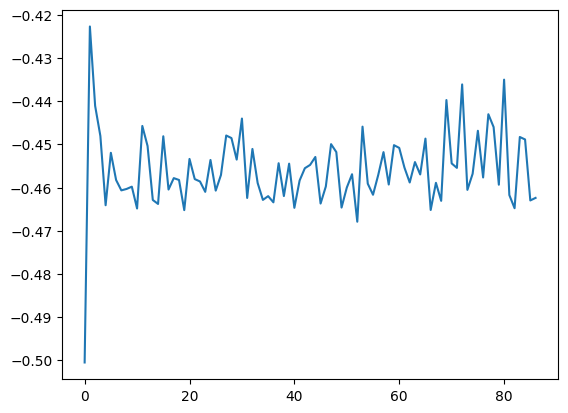

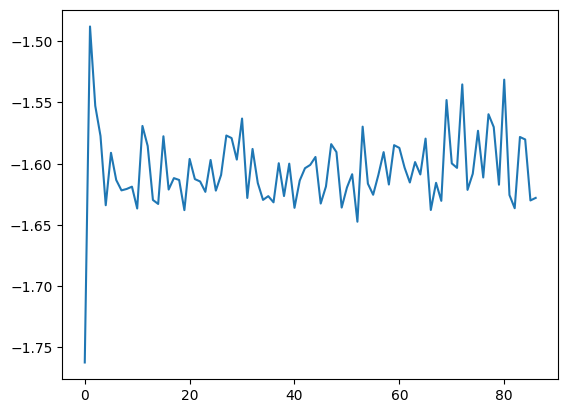

In [6]:
plt.plot(trace[0])
plt.show()
plt.plot(trace[1])
plt.show()

In [7]:
labels

array([2, 1, 1, 1, 1, 0, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 0, 0, 0, 2, 2, 1,
       2, 1, 3, 2, 0, 3, 3, 2, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 2, 1, 0, 3,
       1, 2, 2, 2, 1, 1, 2, 0, 1, 2, 2, 0, 2, 0, 0, 2, 2, 0, 1, 1, 1, 2,
       1, 2, 2, 1, 2, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 2, 1, 1, 0, 0, 1, 1,
       0, 1, 1, 2, 1, 1, 0, 0, 0, 0, 1, 0])

In [8]:
Main.log_likelihood(labels, A.astype(int),3) * 2 * A.shape[0] / np.sum(A)

-0.49757075048598526

In [ ]:
node_labels, theta, trace, best_ll_trace = Main.GreedyLLopt(A.astype(np.int64), 3, 5000)

In [ ]:
plt.plot(trace)
plt.plot(best_ll_trace)
plt.show()

In [ ]:
node_labels